# Allen's pass-archive cleaning approach: three independent clear views per month

**Question.** Does combining a few independent, locally clear Sentinel-2 passes produce more stable maize predictors than using a single best pass?

This notebook reads the team's **unfiltered** `passarchive_v1.duckdb` (Kenya, Malawi, Zimbabwe), works across both archived years, and makes a matched pair of feature arms: `median3` and `best1`. The image decision never uses yield. The field labels are joined only after all image features are fixed.

The pipeline is: local cloud and field-pixel screen → physical reflectance check → one scene per satellite overflight → three best independent overflights per field-month → per-band median → season summary. A month with one or two clear overflights is retained, with its support count. Missing months stay missing; the model must impute and scale *inside each training fold*. This notebook does **not** choose a winning model.

In [1]:
from pathlib import Path
import json, shutil, subprocess, sys
import duckdb, pandas as pd, numpy as np
import matplotlib.pyplot as plt

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'data/passarchive_v1/release/DICTIONARY.md').is_file()), None)
assert ROOT is not None, 'Launch from within the repository'
DB = ROOT / 'data/passarchive_v1/release/passarchive_v1.duckdb'
SCREEN = ROOT / 'data/features/allen_screen_both_maize'
OUT = ROOT / 'data/features/allen_median3'
HANDOFF = ROOT / 'data/passarchive_v1/cleaning'
assert DB.is_file(), 'Put the checksum-verified archive in the path specified by docs/DATA_SETUP.md'
print('Database: data/passarchive_v1/release/passarchive_v1.duckdb')
print('Bytes:', DB.stat().st_size)

Database: data/passarchive_v1/release/passarchive_v1.duckdb
Bytes: 2678075392


## 1. What the source actually contains

The archive includes all maize field-seasons and both the harvest calendar year (`current`) and preceding calendar year (`previous`). We retain both because some growing seasons cross New Year. Recorded planting and harvest dates define a season where both exist and are coherent. Otherwise, the fallback is the harvest calendar year, explicitly flagged as `harvest_calendar_year`; that fallback is only a comparison proxy.

In [2]:
con = duckdb.connect(str(DB), read_only=True)
source = con.execute('''select country_iso3, dataset, count(*) as field_seasons,
    count(*) filter(where planting_date is not null and harvest_date is not null) as both_dates,
    count(*) filter(where usable_at_field_scale) as field_scale_usable
    from fields where crop='maize' group by 1,2 order by 1,2''').df()
con.close()
print(source.to_string(index=False))

country_iso3                        dataset  field_seasons  both_dates  field_scale_usable
         KEN          one_acre_fund_curated            389         294                   0
         KEN             one_acre_fund_full          23674       17061               23159
         MWI                    malawi_2022            529           0                 529
         MWI                    malawi_2023            267           0                 267
         MWI             one_acre_fund_full           2594        1782                1832
         ZWE vision_guided_yield_estimation           5055           0                5055
         ZWE                       zimbabwe           2269        2269                2269


## 2. Local image quality, with no yield labels

The screening script reads the raw pass and pixel tables. It rejects incomplete bands and visibly obstructed point pixels. For polygon fields it checks native SCL pixels inside the stored footprint and requires at least 80% clear vegetation or bare-soil pixels. High local cloud probability and low sun go to review. Whole-scene cloud cover is a weaker ranking signal because it may describe clouds far from the field. Only `keep` images within known crop dates (or with incomplete dates) proceed. **A point observation establishes only the sampled pixel; it cannot prove that the whole field is clear.**

The full screen is cached locally because it is a large intermediate file. To rebuild, this cell runs `select_passarchive_imagery.py` with both archive years and maize only. No raw database values are edited.

In [3]:
if not (SCREEN / 'scene_decisions.parquet').is_file():
    subprocess.run([sys.executable, str(ROOT / 'scripts/quality/select_passarchive_imagery.py'),
                    '--database', str(DB), '--output', str(SCREEN),
                    '--window-kind', 'both', '--crop', 'maize'],
                   cwd=ROOT, check=True)
screen_summary = json.loads((SCREEN / 'summary.json').read_text(encoding='utf-8'))
print({k: screen_summary[k] for k in
       ['scope_fields','candidate_rows','decisions','field_months','window_kind','crop']})

{'scope_fields': 34777, 'candidate_rows': 5427638, 'decisions': {'reject': 1977705, 'review': 66452, 'keep': 3383481}, 'field_months': 834648, 'window_kind': 'both', 'crop': 'maize'}


## 3. Allen's cleaning rule

After the hard quality screen, each of the ten model bands is converted from Sentinel-2 digital number with the scene's published offset: `(DN + offset) / 10000`. All ten converted reflectances must be in `[0, 1]`. For each overflight, choose only its highest-quality product. Rank independent overflights by **50% local clear fraction, 30% local cloud probability, 10% whole-scene cloud cover, 10% sun elevation**. Missing ancillary metadata receives neutral credit. Keep up to three overflights per field-month and take the median of each band. The matched `best1` arm uses the rank-one overflight from exactly the same eligible pool.

This is a predeclared, label-free rule. The weights are a practical hypothesis, not parameters tuned on held-out yields. Median aggregation can suppress residual contamination but may also smooth genuine rapid crop change; Zida's identical-fold model comparison tests that trade-off.

In [4]:
sys.path.insert(0, str(ROOT / 'scripts/quality'))
from allen_median3 import build
summary = build(DB, SCREEN / 'scene_decisions.parquet', OUT)
print(json.dumps({k:v for k,v in summary.items() if k!='source_decisions'}, indent=2))

{
  "scope": "maize; previous and current archive years",
  "converted_scenes": 1519349,
  "valid_reflectance_scenes": 1519166,
  "independent_scenes": 1184079,
  "selected_scenes": 830488,
  "monthly_rows": 834648,
  "field_seasons": 34777,
  "model_rows": 69554,
  "window_rule_counts": {
    "recorded_dates": 21350.0,
    "harvest_calendar_year": 13427.0
  },
  "model_month_coverage": [
    [
      "KEN",
      "best1",
      24063,
      23098,
      6.36
    ],
    [
      "KEN",
      "median3",
      24063,
      23098,
      6.36
    ],
    [
      "MWI",
      "best1",
      3390,
      2628,
      5.28
    ],
    [
      "MWI",
      "median3",
      3390,
      2628,
      5.28
    ],
    [
      "ZWE",
      "best1",
      7324,
      7324,
      9.92
    ],
    [
      "ZWE",
      "median3",
      7324,
      7324,
      9.92
    ]
  ]
}


## 4. Coverage and actual differences

The two arms have the same field-seasons and observed months. The plot shows monthly image support; the table compares optical features produced by one image versus the median of up to three. Differences are data differences, **not** evidence of better yield predictions.

Monthly support (3 = three independent views; 0 = missing):
support            0      1      2       3
country_iso3                              
KEN           395631  39993  59889   81999
MWI            54694   4979   5089   16598
ZWE            44248   9969  14877  106682


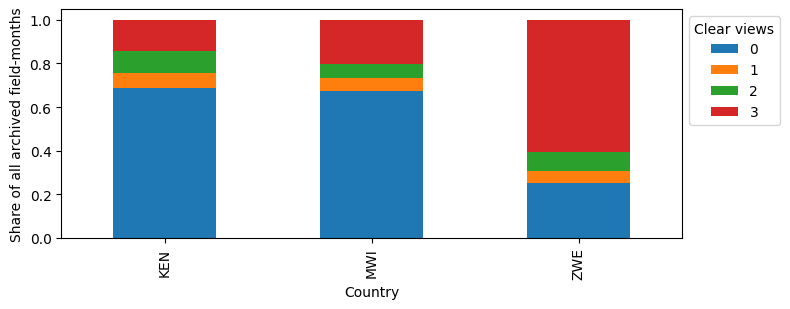

In [5]:
monthly = pd.read_parquet(OUT / 'allen_monthly.parquet',
                          columns=['country_iso3','n_independent_scenes'])
support = (monthly.assign(support=monthly.n_independent_scenes.clip(upper=3))
           .groupby(['country_iso3','support']).size().unstack(fill_value=0))
print('Monthly support (3 = three independent views; 0 = missing):')
print(support.to_string())
ax = support.div(support.sum(axis=1),axis=0).plot.bar(stacked=True, figsize=(8,3.2))
ax.set_ylabel('Share of all archived field-months')
ax.set_xlabel('Country')
ax.legend(title='Clear views', bbox_to_anchor=(1,1))
plt.tight_layout()
plt.show()

In [6]:
model = pd.read_parquet(OUT / 'allen_model_ready.parquet')
wide = model.pivot(index='field_season_id',columns='cleaning_arm',
                   values=['b08_mean','ndvi_mean','months_observed'])
for feature in ['b08_mean','ndvi_mean']:
    difference = (wide[(feature,'median3')]-wide[(feature,'best1')]).abs()
    print(feature, 'n pairs =',difference.notna().sum(),
          'median absolute difference =',round(difference.median(),4),
          '90th percentile =',round(difference.quantile(.9),4))
print('Season-window rules:')
print(model.loc[model.cleaning_arm=='median3','window_rule'].value_counts().to_string())

b08_mean n pairs = 33050 median absolute difference = 0.0056 90th percentile = 0.0174
ndvi_mean n pairs = 33050 median absolute difference = 0.0107 90th percentile = 0.0349
Season-window rules:
window_rule
recorded_dates           21350
harvest_calendar_year    13427


## 5. Quality checks and model handoff

Every field-season appears once per arm. Both arms use the same month coverage. The output carries `field_season_id`, country, dataset, year, location quality, label status, yield in t/ha, ten mean reflectances, NDVI summary and support counts. The labels were joined after cleaning, so they cannot influence scene selection. Zida should use identical fields and spatial folds for both arms, and fit imputation, scaling and Ridge or other baseline **within each training fold**. Keep the existing fold-0 reserve untouched. For a strict field-level analysis, require `usable_at_field_scale` and inspect `label_status`.

In [7]:
assert len(model)==2*model.field_season_id.nunique()
assert not model.duplicated(['field_season_id','cleaning_arm']).any()
assert (wide[('months_observed','median3')]==wide[('months_observed','best1')]).all()
for band in ['b02','b03','b04','b05','b06','b07','b08','b8a','b11','b12']:
    x=model[f'{band}_mean'].dropna()
    assert x.between(0,1).all(), band
assert set(model.cleaning_arm)=={'median3','best1'}
HANDOFF.mkdir(parents=True,exist_ok=True)
shutil.copy2(OUT/'allen_model_ready.parquet', HANDOFF/'allen_model_ready.parquet')
print('Checks passed. Shareable model handoff: data/passarchive_v1/cleaning/allen_model_ready.parquet')
print('Rows:',len(model),'Fields:',model.field_season_id.nunique())

Checks passed. Shareable model handoff: data/passarchive_v1/cleaning/allen_model_ready.parquet
Rows: 69554 Fields: 34777


### Limits and next comparison

Most Kenyan and Zimbabwe locations are points, so local cloud checks apply to one pixel, not a verified field boundary. Some Malawi and Zimbabwe datasets lack planting/harvest dates; their `harvest_calendar_year` features are a deliberately flagged proxy. A month with zero valid images remains missing. `best1` and `median3` preserve the same sample cohort, letting Zida compare the effect of the cleaning choice with the same model and folds. Do not choose this policy using the held-out fold or interpret a larger number of retained images as improved prediction by itself.

Local audit outputs are in `data/features/allen_median3/` (ignored by Git). The compact, versioned handoff is `data/passarchive_v1/cleaning/allen_model_ready.parquet`. See `data/passarchive_v1/cleaning/README.md` for the column contract.